In [1]:
# Notebooks live in Notebooks/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())

cwd: /home/lotan.amit/WhatDoLLMsWant


# Real laptops — do the trends of the synthetic laptops hold? (2026-11-14)

The chosen figures of `figs4nir.ipynb` and `figs4nir2.ipynb`, rebuilt on the **real laptops** batch
(`data/real_laptops/`, jobs 1498397–1498402). Each figure keeps the number of the figure it copies, with an
**r** at the end (F2 → **F2r**), and the same colours.

**What is different from the synthetic set**

| | synthetic laptops | real laptops |
|---|---|---|
| items | 45 = 5 brands × 3 screens × 3 RAM, nothing else in the text | 60 real products: name, CPU, disk, GPU, weight, price, ... |
| features we name | all of the item | 3 of many: brand, screen, RAM |
| contracts | 14-inch, 8GB, 4GB and some pairs | none + 6 singles + 12 pairs + 8 triples over Dell / HP × 14 / 15.6-inch × 4 / 8GB |
| pairs | all, 5 templates | none + singles: all 1,770; the 20 compounds: a fixed 500. Template 0 only |
| models | 12 | qwen-72B, gemma-27B, olmo-32B |

**Three choices made here** (say if you want another one):

1. **Rank = the laptop's own utility** (one free number per laptop, fitted on the margins). In the synthetic
   set the rank came from the additive fit; here two laptops with the same brand, screen and RAM are still
   different products, so the additive fit cannot rank them.
2. **Levels are binned for the additive fit only**: screen `<14 / 14 / 15.6 / >15.6`, RAM `≤4GB / 8GB / ≥12GB`,
   brand `Dell / HP / Lenovo / Asus / other`. Seven of the 19 raw levels have one or two laptops.
3. **A compound contract has 500 pairs, not 1,770.** Section 0 checks how much that moves the ranks.

**D** = margin of laptop x over y with the slot effect averaged out (both orders). "x wins" = D > 0.

## What came out

Numbers are qwen-72B / gemma-27B / olmo-32B unless said otherwise.

| # | Trend on the synthetic laptops | On the real laptops | Holds? |
|---|---|---|---|
| 1 | A contract pulls the laptops that meet it to the top (F1–F4) | The 10 laptops that are 14-inch + 8GB: mean rank 19 / 22 / 18 with no contract → 5.6 / 6.1 / 6.5 under the contract (5.5 is the best possible). 9 / 9 / 8 of the top 10 meet it | **yes** |
| 2 | Inside the contract the model keeps its own taste (under `14-inch`, more RAM is still on top) | Under `14-inch` alone, 9 of the top 10 are already the 8GB ones. The 14-inch laptops with other RAM climb to rank 16–22, then fall back to 28–39 when `8GB` is added | **yes** |
| 3 | Asking for the level the model likes least (`4GB`) still works (F14–F16) | The 6 laptops that are 14-inch + 4GB: mean rank 52 / 48 / 47 → 5.2 / 9.0 / 7.3 (best possible 3.5). 5 / 4 / 4 of the 6 are in the top 10 | **yes, weaker** |
| 4 | When obeying costs, the large models obey in 100% of the pairs (F11) | 97% / 87% / 90% of the conflict pairs with one request, 99% / 99% / 92% with three. κ is 1.8–3.4 everywhere, so the push is far past "indifferent". Lowest cell 62% | **mostly** — high, not 100% |
| 5 | RAM is the heaviest feature (F12) | Range of the RAM weights 11.3 / 24.6 / 6.2, screen 8.2 / 7.1 / 3.3, brand 4.1 / 6.7 / 1.0. More RAM wins 86% / 95% / 89% of the pairs where RAM differs | **yes** |
| 6 | The additive fit explains nearly all of a laptop's utility: R² 0.97–0.996 (F7) | R² 0.77 / 0.77 / 0.76 with no contract, 0.80–0.92 under a contract | **no** — expected: three features of many. New: the fit gets *better* under a contract |
| 7 | Borda rank = BT rank, ρ ≈ 0.99 (F9, F10) | Per-laptop BT: ρ 0.96–0.995. Additive BT: 0.77–0.91 | **yes** for the per-laptop fit |
| 8 | The slot decides 15–30% of the comparisons (T1) | 29% / 11% / 27% with no contract; 12% / 12% / 13% with three requests | **yes**. New: it falls as the contract gets longer |
| 9 | The more the user says, the higher their laptop, and the order of saying matters (figs4nir2 B) | Rank of the user's best laptop, mean of 8 users: 23 / 26 / 23 with nothing said → 3–4 after the best first attribute (10–12 after the worst) → 1.1–1.8 → 1.0–1.1 | **yes** |
| 10 | Apple loses ground under any contract (F13) | No Apple here. Dell, HP, Lenovo and Asus move by at most 1.8; "other" (5 laptops) falls by 1.1–4.0 | **cannot be tested** |

**Read with care**

- **Ranks under a compound contract come from 500 pairs.** Section 0: against all 1,770 pairs the order is
  nearly the same (Spearman ≥ 0.985, a laptop moves 1.4–2.0 places on average, 10 at most), but the laptop in
  place **1** is the same in only 3 / 1 / 5 of 7 runs. So "rank 1" vs "rank 2" at two or three requests is
  inside the noise; the top 5 is solid (4 of 5 shared).
- **Real laptops are never "all else equal".** A conflict pair differs in CPU, disk and price too, so 87% is
  not the same statement as the synthetic 100%.
- **γ for qwen-72B has the other sign** here (+2.8, favours the first slot; −3.9 on the synthetic set). Not
  looked into.
- One template, three models.

## Setup

Loading, the fits and the plot helpers. Nothing to read here unless a figure looks wrong.

In [2]:
import json, glob, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
from matplotlib.lines import Line2D
from matplotlib.colors import to_rgb

from src.bt import FeatureBT

pd.set_option("display.width", 220)
SAVE, FIGDIR = True, "figs/real_laptops_trends"
os.makedirs(FIGDIR, exist_ok=True)

BASE, FRAME = "data/real_laptops", "shopping"
MODELS = [("qwen", "72"), ("gemma", "27"), ("olmo", "32")]
HEADLINE = ("qwen", "72")
FEATS = ["brand", "screen", "ram"]

ITEMS = pd.read_csv(f"{BASE}/design/items.csv").set_index("id")
CON = pd.read_csv(f"{BASE}/design/contracts.csv")
PAIRS500 = pd.read_csv(f"{BASE}/design/compound_pairs.csv")
IDS = list(ITEMS.index)
N = len(IDS)
POS = {i: k for k, i in enumerate(IDS)}
LVL = {i: dict(ITEMS.loc[i, FEATS]) for i in IDS}                  # the three named features, as in scores.csv


def bin_screen(s):
    v = float(s.replace("-inch", ""))
    return "<14" if v < 14 else "14" if v == 14 else "15.6" if v == 15.6 else ">15.6"


def bin_ram(r):
    g = int(r.replace("GB", ""))
    return "≤4GB" if g <= 4 else "8GB" if g == 8 else "≥12GB"


def bin_brand(b):
    return b if b in ("Dell", "HP", "Lenovo", "Asus") else "other"


BIN = {"brand": bin_brand, "screen": bin_screen, "ram": bin_ram}
BLEVELS = {"brand": ["Dell", "HP", "Lenovo", "Asus", "other"], "screen": ["<14", "14", "15.6", ">15.6"],
           "ram": ["≤4GB", "8GB", "≥12GB"]}
BINNED = pd.DataFrame({f: ITEMS[f].map(BIN[f]) for f in FEATS})
print("laptops per binned level:", {f: BINNED[f].value_counts().reindex(BLEVELS[f]).to_dict() for f in FEATS})

SURFACE, INK, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#d6d5d1",
    "axes.labelcolor": INK, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "axes.grid": True,
    "grid.color": "#e8e7e3", "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "figure.dpi": 110, "font.size": 10,
    "savefig.bbox": "tight", "savefig.dpi": 200,
})
# Same colours as figs4nir: one per requirement, purple when both are met, gray when none.
PINK, SKY, PURPLE, GRAY = "#e87ba4", "#6da7ec", "#4a3aa7", "#c9c8c4"
REQ_COLOR = {"screen": PINK, "ram": SKY}
MIX = {frozenset(): GRAY, frozenset({"screen"}): PINK, frozenset({"ram"}): SKY,
       frozenset({"screen", "ram"}): PURPLE}
FEATURE_COLOR = {"brand": "#2a78d6", "screen": "#eb6834", "ram": "#1baf7a"}
MODEL_COLOR = {("qwen", "72"): "#2a78d6", ("gemma", "27"): "#eb6834", ("olmo", "32"): "#1baf7a"}
MODEL_MARK = {("qwen", "72"): "o", ("gemma", "27"): "s", ("olmo", "32"): "^"}


def name(m):
    return f"{m[0]}-{m[1]}B"


def save(fig, fname):
    if SAVE:
        fig.savefig(os.path.join(FIGDIR, fname + ".png"), facecolor=SURFACE)


def parse(cid):
    return dict(p.split("=") for p in cid.split("+")) if cid != "none" else {}


def cid_of(con):
    return "+".join(f"{f}={v}" for f, v in sorted(con.items())) or "none"


def met(lvl, con):
    """Which requirements of contract `con` this laptop meets."""
    return frozenset(f for f, v in con.items() if lvl.get(f) == v)


def short(i):
    """Label of one laptop: the three named features and the price (several laptops share the three)."""
    r = ITEMS.loc[i]
    return f"{r.brand} {r.screen.replace('-inch', 'in')} {r.ram} €{r.Price_euros:.0f}"

laptops per binned level: {'brand': {'Dell': 18, 'HP': 18, 'Lenovo': 10, 'Asus': 9, 'other': 5}, 'screen': {'<14': 8, '14': 17, '15.6': 30, '>15.6': 5}, 'ram': {'≤4GB': 21, '8GB': 33, '≥12GB': 6}}


In [3]:
def load():
    """Complete runs only: config.json without scores.csv, or with too few rows, is a dead job."""
    R = {}
    for cf in sorted(glob.glob(f"{BASE}/*/config.json")):
        sc = cf.replace("config.json", "scores.csv")
        if not os.path.isfile(sc):
            continue
        c = json.load(open(cf))
        d = pd.read_csv(sc)
        if c["frame"]["name"] != FRAME or len(d) != c["n_rows"]:
            continue
        key = (c["model_family"], str(c["model_size"]), c["constraints_id"])
        assert key not in R, f"two complete runs share {key}"
        R[key] = d
    return R


RUNS = load()
CIDS = list(CON.constraints_id)
assert len(RUNS) == len(MODELS) * len(CIDS) and all((*m, c) in RUNS for m in MODELS for c in CIDS)
print(len(RUNS), "runs =", len(MODELS), "models x", len(CIDS), "contracts")


def duel(d):
    """D[x, y] = margin of x over y, slot effect averaged out (> 0: x wins). NaN = pair not asked."""
    M = np.full((N, N), np.nan)
    M[d.a_id.map(POS).values, d.b_id.map(POS).values] = (d.score_a - d.score_b).values
    return pd.DataFrame((M - M.T) / 2, index=IDS, columns=IDS)


def item_fit(d):
    """BT with ONE free utility per laptop, by OLS on the margins: m = gamma + u_a - u_b.
    Works on the 500-pair runs too. Returns (utilities centred to mean 0, gamma, R2)."""
    a, b = d.a_id.map(POS).values, d.b_id.map(POS).values
    n = len(d)
    X = np.zeros((n, N))
    X[np.arange(n), a] += 1
    X[np.arange(n), b] -= 1
    X = np.column_stack([np.ones(n), X[:, 1:]])           # drop one laptop: it is the reference
    y = (d.score_a - d.score_b).values
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    u = np.r_[0.0, beta[1:]]
    r2 = 1 - ((y - X @ beta) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return pd.Series(u - u.mean(), index=IDS), beta[0], r2


def feat_frame(d, binned=True):
    """scores.csv with only the three named features (FeatureBT fits every a_* column, so a_id must go)."""
    out = pd.DataFrame({"score_a": d.score_a.values, "score_b": d.score_b.values})
    for s in "ab":
        for f in FEATS:
            out[f"{s}_{f}"] = d[f"{s}_{f}"].map(BIN[f]).values if binned else d[f"{s}_{f}"].values
    return out


def additive_fit(d, binned=True):
    """The additive fit: u = w_brand + w_screen + w_ram. Returns (FeatureBT, utility per laptop, mean 0)."""
    f = FeatureBT(r2_warn=None).fit(feat_frame(d, binned))
    src = BINNED if binned else ITEMS
    u = pd.Series({i: f.utility({ft: src.loc[i, ft] for ft in FEATS}) for i in IDS})
    return f, u - u.mean()


def rank_desc(x, ties="first"):
    return pd.Series(x).rank(ascending=False, method=ties)


UTIL, GAMMA, R2_ITEM = {}, {}, {}
for key, d in RUNS.items():
    UTIL[key], GAMMA[key], R2_ITEM[key] = item_fit(d)
RANK = {m: pd.DataFrame({c: rank_desc(UTIL[(*m, c)]) for c in CIDS}) for m in MODELS}     # 1 = most preferred
DUEL = {key: duel(d) for key, d in RUNS.items()}
print("R2 of the per-laptop fit, median over the 27 contracts:",
      {name(m): round(float(np.median([R2_ITEM[(*m, c)] for c in CIDS])), 3) for m in MODELS})

81 runs = 3 models x 27 contracts
R2 of the per-laptop fit, median over the 27 contracts: {'qwen-72B': 0.886, 'gemma-27B': 0.816, 'olmo-32B': 0.911}


In [4]:
def make_path(ids, title):
    """A contract path: ids, each contract as {feature: level}, the order the requirements are added."""
    cons = [parse(c) for c in ids]
    order = []
    for con in cons:
        order += sorted(set(con) - set(order))
    lab = [" + ".join(con[f] for f in order if f in con) or "no contract" for con in cons]
    sh = [l.replace("-inch", "in").replace(" + ", "+").replace("no contract", "none") for l in lab]
    return dict(ids=ids, cons=cons, order=order, lab=lab, short=sh, title=title)


PA = make_path(["none", "screen=14-inch", "ram=8GB+screen=14-inch"], "path A: 14-inch first")
PB = make_path(["none", "ram=8GB", "ram=8GB+screen=14-inch"], "path B: 8GB first")
PC = make_path(["none", "ram=4GB", "ram=4GB+screen=14-inch"], "path C: 4GB first")
PD = make_path(["none", "screen=14-inch", "ram=4GB+screen=14-inch"], "path D: 14-inch, then + 4GB")


def spread(ys, gap):
    """Push label positions apart so that no two are closer than `gap`."""
    out = np.array(ys, dtype=float)
    order = np.argsort(out)
    for a, b in zip(order[:-1], order[1:]):
        out[b] = max(out[b], out[a] + gap)
    return out


def bump(ax, R, path, lvl_of, label_of=None, fs=7, nmax=N, sides=("left", "right"), gap=0):
    """One line per row of R (columns: contract ids); x = contract on `path`, y = rank (1 on top).
    Segment i -> i+1 is coloured by the requirements of contract i+1 the row meets; the point at i by
    those of contract i. Rows that meet the full contract get a bold label."""
    R, CONS = R[path["ids"]], path["cons"]
    x = np.arange(len(CONS))
    labels = label_of is not None
    ms = 5 if labels else 2.5
    lw = (1.8, 1.0) if labels else (1.2, 0.7)             # (coloured, gray)
    for key, row in R.iterrows():
        lvl, y = lvl_of(key), row.values
        for i in range(len(CONS) - 1):
            c = MIX[met(lvl, CONS[i + 1])]
            ax.plot(x[i:i + 2], y[i:i + 2], color=c, lw=lw[c == GRAY], zorder=1 if c == GRAY else 2,
                    solid_capstyle="round")
        for i in range(len(CONS)):
            ax.plot(x[i], y[i], ls="", marker="o", color=MIX[met(lvl, CONS[i])], ms=ms, mew=0, zorder=3)
    for side in (sides if labels else ()):
        xi, ha, off = (0, "right", -0.06) if side == "left" else (x[-1], "left", 0.06)
        ys = spread(R.iloc[:, xi].values, gap) if gap else R.iloc[:, xi].values
        for key, yy in zip(R.index, ys):
            lvl = lvl_of(key)
            full = met(lvl, CONS[-1]) == frozenset(CONS[-1])
            ax.text(xi + off, yy, label_of(key), ha=ha, va="center", fontsize=fs,
                    color=INK if met(lvl, CONS[-1]) else INK_MUTED, fontweight="bold" if full else "normal")
    ax.set_xticks(x, path["lab"])
    ax.set_xlim(-(0.75 if labels and "left" in sides else 0.08), x[-1] + (0.75 if labels and "right" in sides else 0.08))
    ax.set_ylim(nmax + 0.8, 0.2)
    ax.set_yticks([1] + list(range(10, nmax + 1, 10)))
    ax.grid(axis="x", visible=False)


def contract_legend(fig, path, y=1.0, fs=8):
    full = path["cons"][-1]
    hs = [Line2D([], [], color=REQ_COLOR[f], lw=2.2, label=f"meets {full[f]}") for f in path["order"]]
    hs += [Line2D([], [], color=PURPLE, lw=2.2, label="meets both"), Line2D([], [], color=GRAY, lw=2.2, label="meets none")]
    fig.legend(handles=hs, loc="lower left", ncol=len(hs), bbox_to_anchor=(0.02, y), frameon=False,
               fontsize=fs, handlelength=2.2, columnspacing=1.4)


def group_rank(m, path):
    """Mean rank of the laptops in each group: which requirements of the path's LAST contract they meet."""
    full = path["cons"][-1]
    g = pd.Series({i: met(LVL[i], full) for i in IDS})
    G = RANK[m][path["ids"]].groupby(g).mean()
    G["n"] = g.value_counts()
    return G


def group_label(key, full, n):
    if not key:
        return f"neither (n={n})"
    if key == frozenset(full):
        return " + ".join(full[f] for f in sorted(full, key=lambda f: f != "screen")).replace("-inch", "in") + f" (n={n})"
    f = next(iter(key))
    return f"{full[f].replace('-inch', 'in')} only (n={n})"


def path_grid(paths, title, fname, grouped=False):
    """Rows = paths, columns = models. grouped=False: all 60 laptops; True: the 4 groups, labelled."""
    fig, axes = plt.subplots(len(paths), 3, figsize=(14, (3.9 if grouped else 4.6) * len(paths)),
                             sharey=True, squeeze=False)
    for r, path in enumerate(paths):
        full = path["cons"][-1]
        for ax, m in zip(axes[r], MODELS):
            if grouped:
                G = group_rank(m, path)
                bump(ax, G, path, lvl_of=lambda k: {f: full[f] for f in k},
                     label_of=lambda k: group_label(k, full, int(G.loc[[k], "n"].iloc[0])), fs=7.5,
                     sides=("right",), gap=2.8)
            else:
                bump(ax, RANK[m], path, lvl_of=lambda i: LVL[i])
            ax.set_title(f"{name(m)} - {path['title']}", loc="left", fontsize=10, fontweight="bold")
            ax.set_xticks(range(len(path["ids"])), path["lab"], fontsize=8.5)
        axes[r, 0].set_ylabel("mean rank of the group (of 60)" if grouped else "rank (1 = most preferred)")
    top = 0.93 if len(paths) > 1 else 0.86
    fig.tight_layout(rect=(0, 0, 1, top))
    hs = [Line2D([], [], color=PINK, lw=2.2, label="meets the screen request"),
          Line2D([], [], color=SKY, lw=2.2, label="meets the RAM request"),
          Line2D([], [], color=PURPLE, lw=2.2, label="meets both"), Line2D([], [], color=GRAY, lw=2.2, label="meets none")]
    fig.legend(handles=hs, loc="lower left", ncol=4, bbox_to_anchor=(0.01, top + 0.005), frameon=False, fontsize=9)
    fig.suptitle(title, x=0.01, y=1.0, ha="left", fontweight="bold")
    save(fig, fname)
    plt.show()

## 0 — Can we trust ranks from 500 pairs?

The 20 compound contracts were scored on 500 of the 1,770 pairs. Test on the 7 runs that have all pairs:
fit the laptops' utilities on all pairs, then again on only those 500, and compare the two rankings.

In [5]:
key500 = set(zip(PAIRS500.id_x, PAIRS500.id_y)) | set(zip(PAIRS500.id_y, PAIRS500.id_x))
rows = []
for m in MODELS:
    for c in CIDS[:7]:
        d = RUNS[(*m, c)]
        sub = d[[k in key500 for k in zip(d.a_id, d.b_id)]]
        u_all, u_500 = UTIL[(*m, c)], item_fit(sub)[0]
        r_all, r_500 = rank_desc(u_all), rank_desc(u_500)
        rows.append(dict(model=name(m), contract=c, spearman=st.spearmanr(u_all, u_500)[0],
                         mean_rank_move=(r_all - r_500).abs().mean(), max_rank_move=(r_all - r_500).abs().max(),
                         same_top1=r_all.idxmin() == r_500.idxmin(),
                         top5_shared=len(set(r_all.nsmallest(5).index) & set(r_500.nsmallest(5).index))))
V = pd.DataFrame(rows)
print(V.groupby("model").agg(spearman_min=("spearman", "min"), mean_rank_move=("mean_rank_move", "mean"),
                             max_rank_move=("max_rank_move", "max"), same_top1=("same_top1", "sum"),
                             top5_shared_mean=("top5_shared", "mean")).round(3).to_string())
print("\npairs per laptop in the 500:", pd.concat([PAIRS500.id_x, PAIRS500.id_y]).value_counts().describe()[["min", "50%", "max"]].to_dict())

           spearman_min  mean_rank_move  max_rank_move  same_top1  top5_shared_mean
model                                                                              
gemma-27B         0.985           1.976           10.0          1             4.000
olmo-32B          0.990           1.371            8.0          5             4.286
qwen-72B          0.988           1.448            7.0          3             4.000

pairs per laptop in the 500: {'min': 9.0, '50%': 17.0, 'max': 24.0}


# Graph 1 — laptop rank along the contract path

Same two paths as `figs4nir`, and the same contracts: **A** no contract → `14-inch` → `14-inch + 8GB`,
**B** no contract → `8GB` → `8GB + 14-inch`. A segment is coloured by which requirements of the contract it
*leads into* the laptop meets: 14-inch = pink, 8GB = light blue, both = purple, none = gray.

## F1r — all 60 laptops, one model, path A

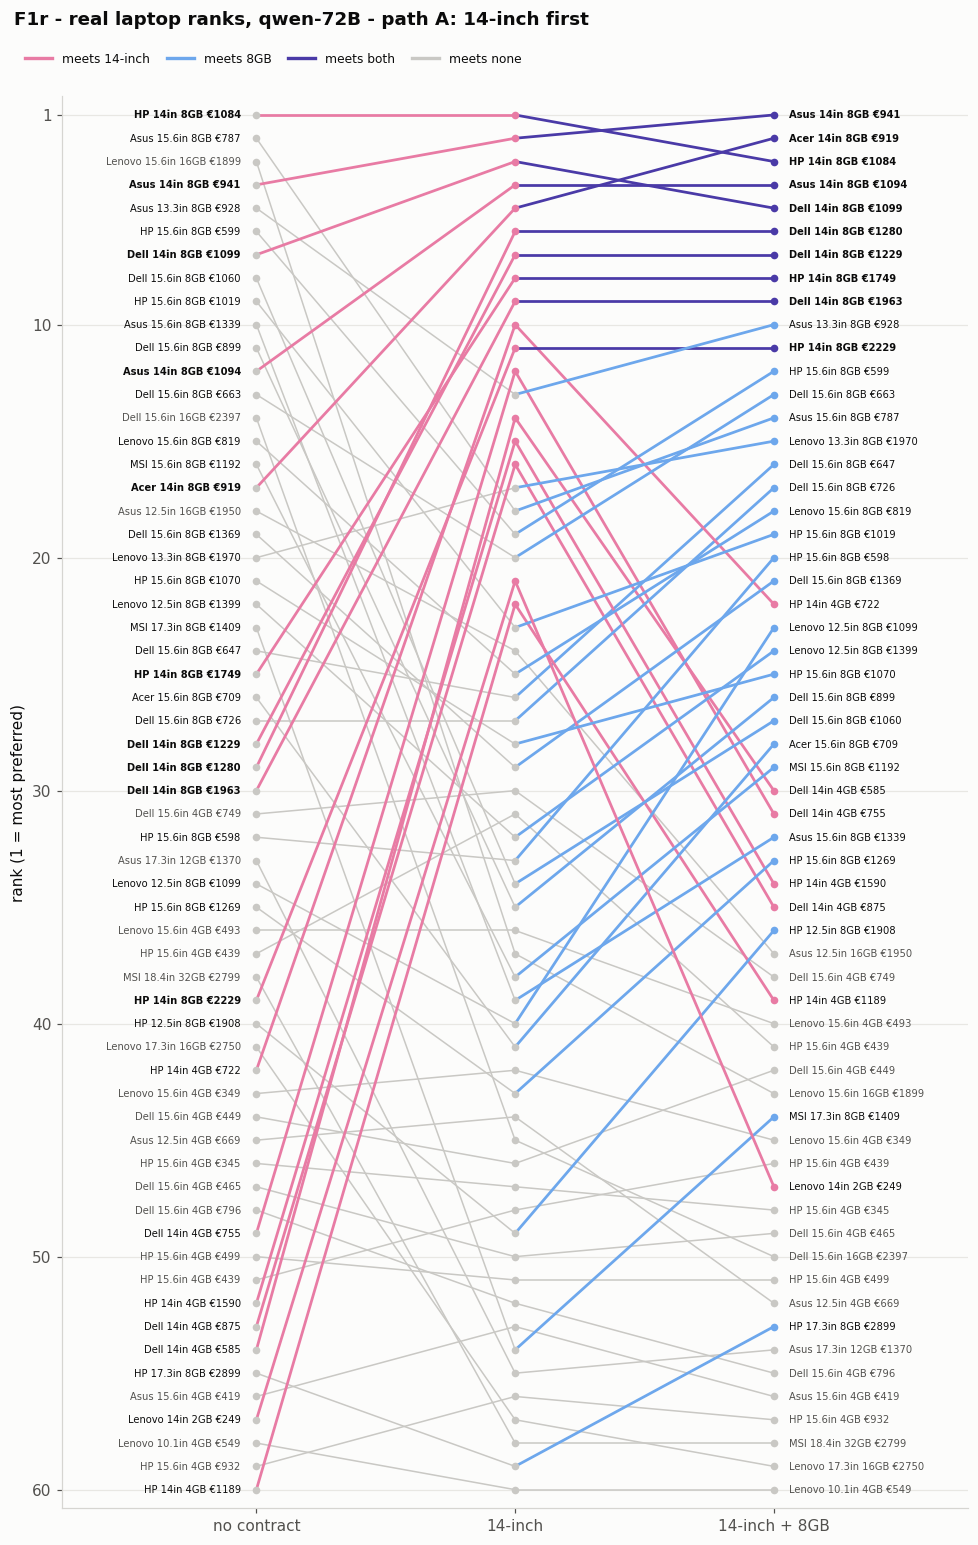

In [6]:
fig, ax = plt.subplots(figsize=(9, 14))
bump(ax, RANK[HEADLINE], PA, lvl_of=lambda i: LVL[i], label_of=short, fs=6.5)
ax.set_ylabel("rank (1 = most preferred)")
fig.tight_layout(rect=(0, 0, 1, 0.955))
contract_legend(fig, PA, y=0.957)
fig.suptitle(f"F1r - real laptop ranks, {name(HEADLINE)} - {PA['title']}", x=0.02, y=1.0, ha="left", fontweight="bold")
save(fig, "F1r_rank_" + name(HEADLINE))
plt.show()

## F2r — all 60 laptops, the three models, paths A and B

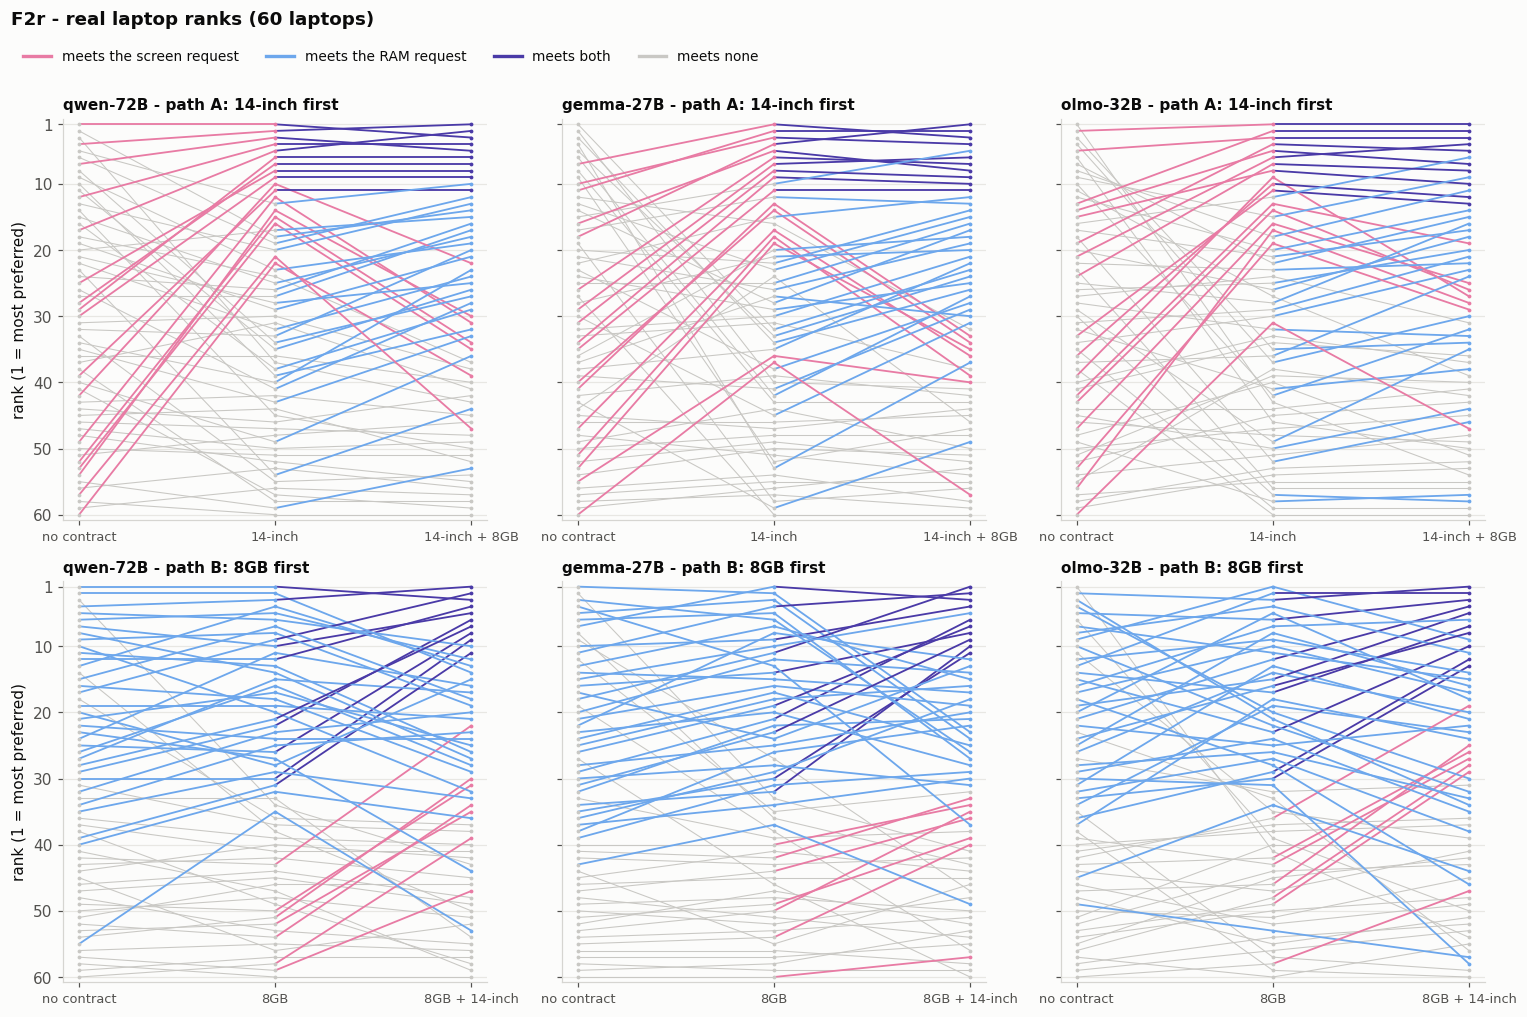

In [7]:
path_grid([PA, PB], "F2r - real laptop ranks (60 laptops)", "F2r_rank_grid")

## F4r — grouped by what the laptop meets

In the synthetic set F3 / F4 averaged the 5 brands of one spec. Here the laptops are grouped by which
requirements of the **last** contract of the path they meet: both, only the screen, only the RAM, neither.
One line = the mean rank of that group. The table gives the same numbers, and how many of the top 10 meet
the full contract.

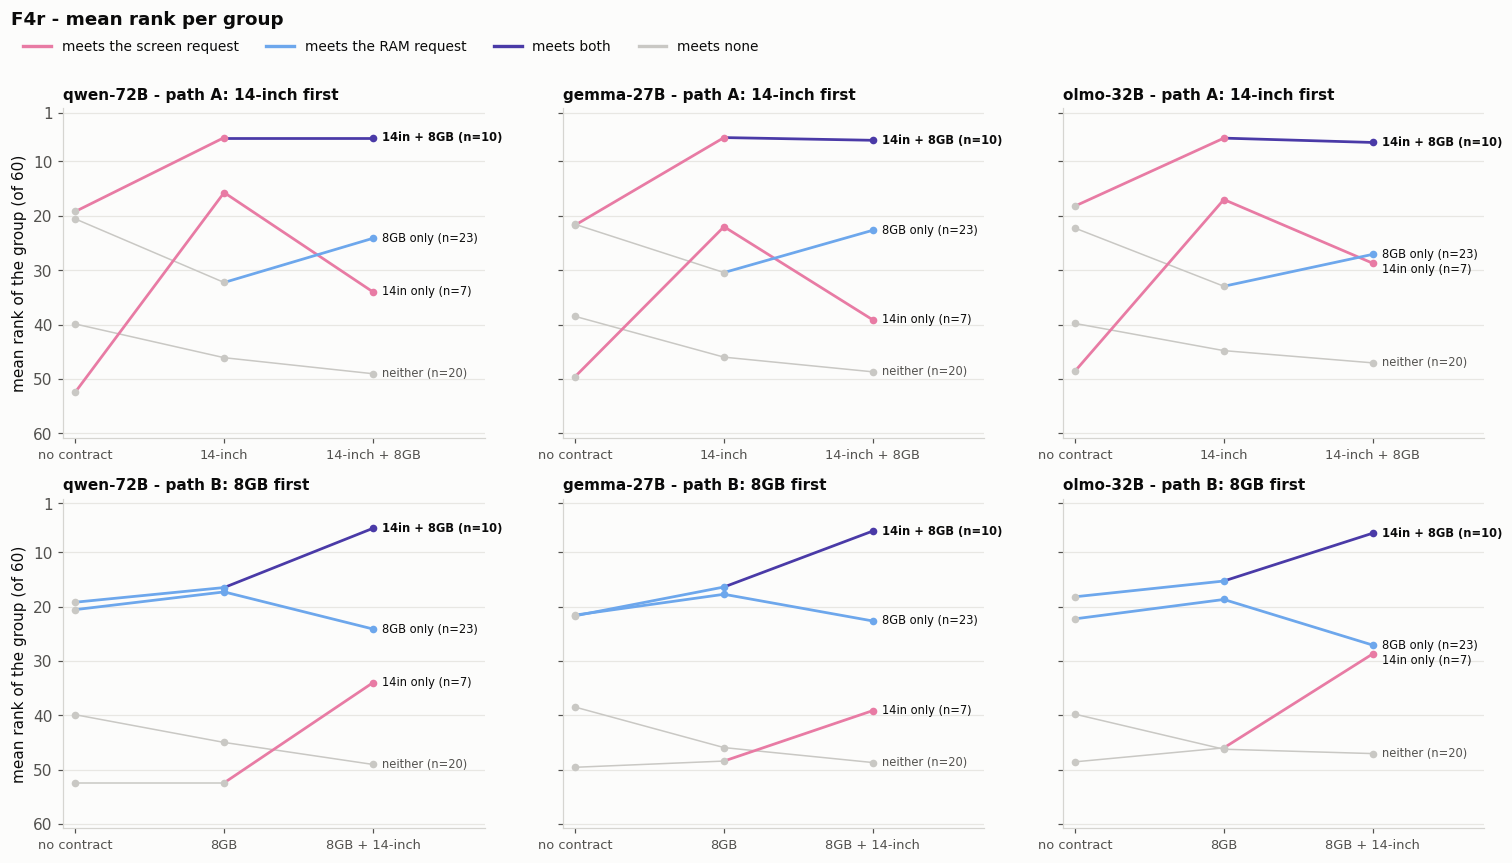

path A: 14-inch first - the 10 laptops that meet the full contract (best possible mean rank: 5.5)
    model  mean rank | none  mean rank | 14in  mean rank | 14in+8GB  in top 10 | none  in top 10 | 14in  in top 10 | 14in+8GB
 qwen-72B              19.2               5.6                   5.6                 3                 9                     9
gemma-27B              21.7               5.6                   6.1                 2                 9                     9
 olmo-32B              18.2               5.7                   6.5                 2                 9                     8

path B: 8GB first - the 10 laptops that meet the full contract (best possible mean rank: 5.5)
    model  mean rank | none  mean rank | 8GB  mean rank | 8GB+14in  in top 10 | none  in top 10 | 8GB  in top 10 | 8GB+14in
 qwen-72B              19.2             16.5                   5.6                 3                4                     9
gemma-27B              21.7             16.4           

In [8]:
path_grid([PA, PB], "F4r - mean rank per group", "F4r_rank_by_group_grid", grouped=True)


def group_table(paths):
    for path in paths:
        full = path["cons"][-1]
        both = [i for i in IDS if met(LVL[i], full) == frozenset(full)]
        rows = []
        for m in MODELS:
            G = group_rank(m, path)
            row = {"model": name(m)}
            for c, l in zip(path["ids"], path["short"]):
                row[f"mean rank | {l}"] = G.loc[[frozenset(full)], c].iloc[0]
            for c, l in zip(path["ids"], path["short"]):
                row[f"in top 10 | {l}"] = int(RANK[m][c].loc[both].le(10).sum())
            rows.append(row)
        print(f"{path['title']} - the {len(both)} laptops that meet the full contract (best possible mean rank: {(len(both) + 1) / 2})")
        print(pd.DataFrame(rows).round(1).to_string(index=False))
        print()


group_table([PA, PB])

# Graph 6 — asking for 4GB, the RAM level the models like least

**C** no contract → `4GB` → `4GB + 14-inch`, **D** no contract → `14-inch` → `14-inch + 4GB`.
Light blue = meets 4GB.

## F15r — all 60 laptops · F16r — grouped

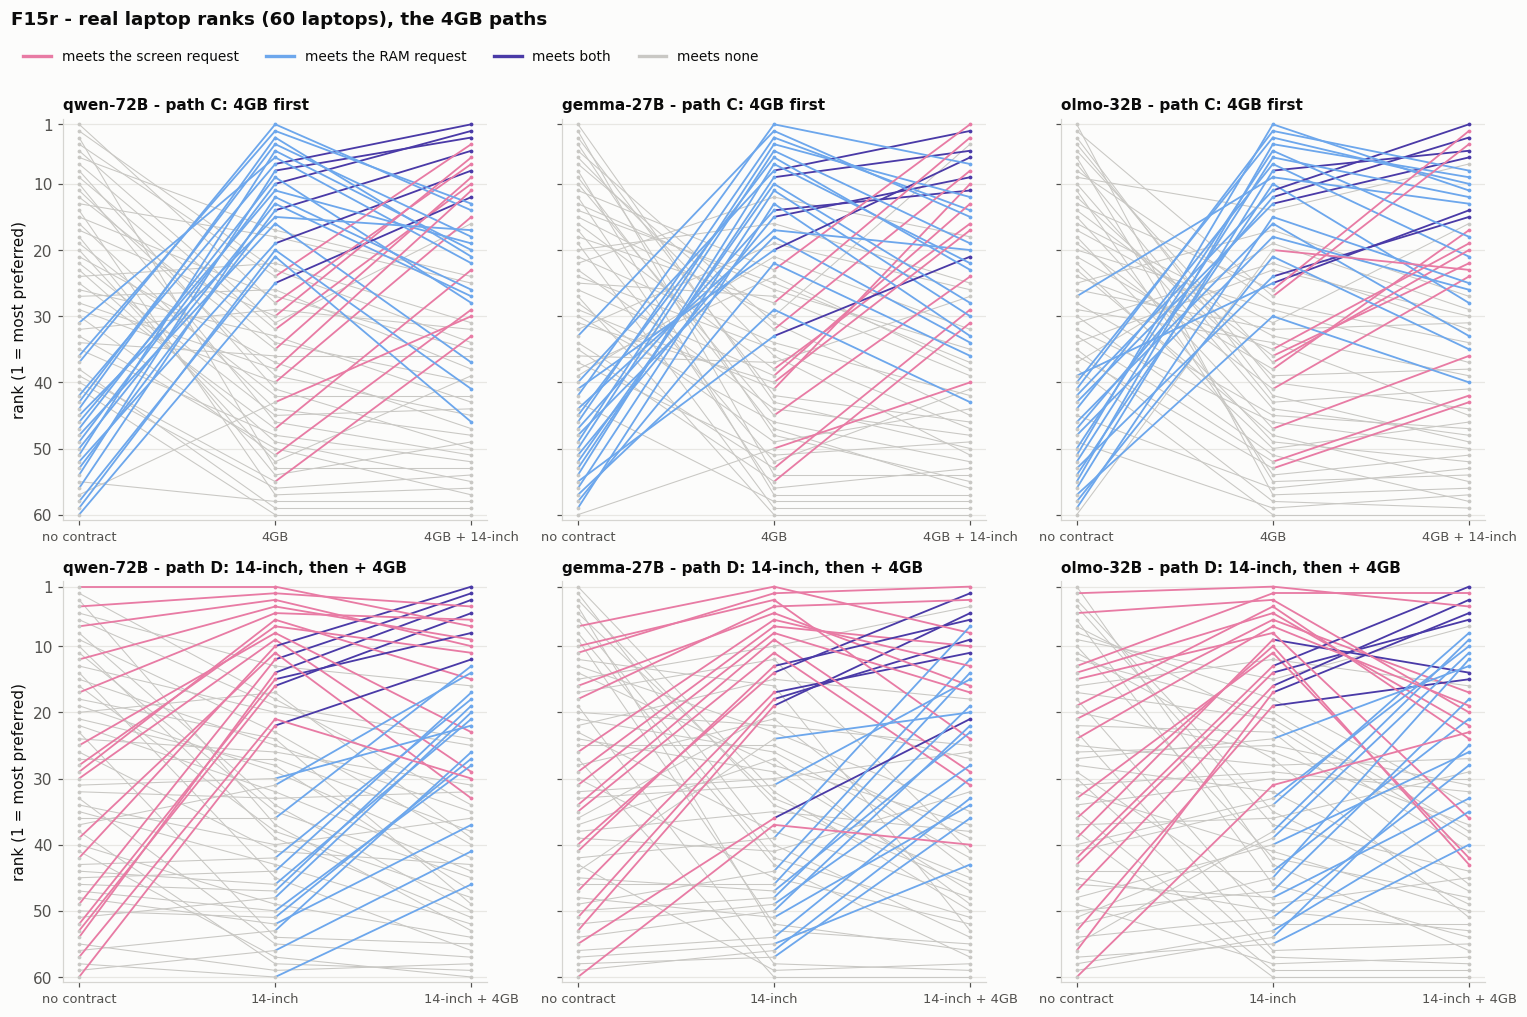

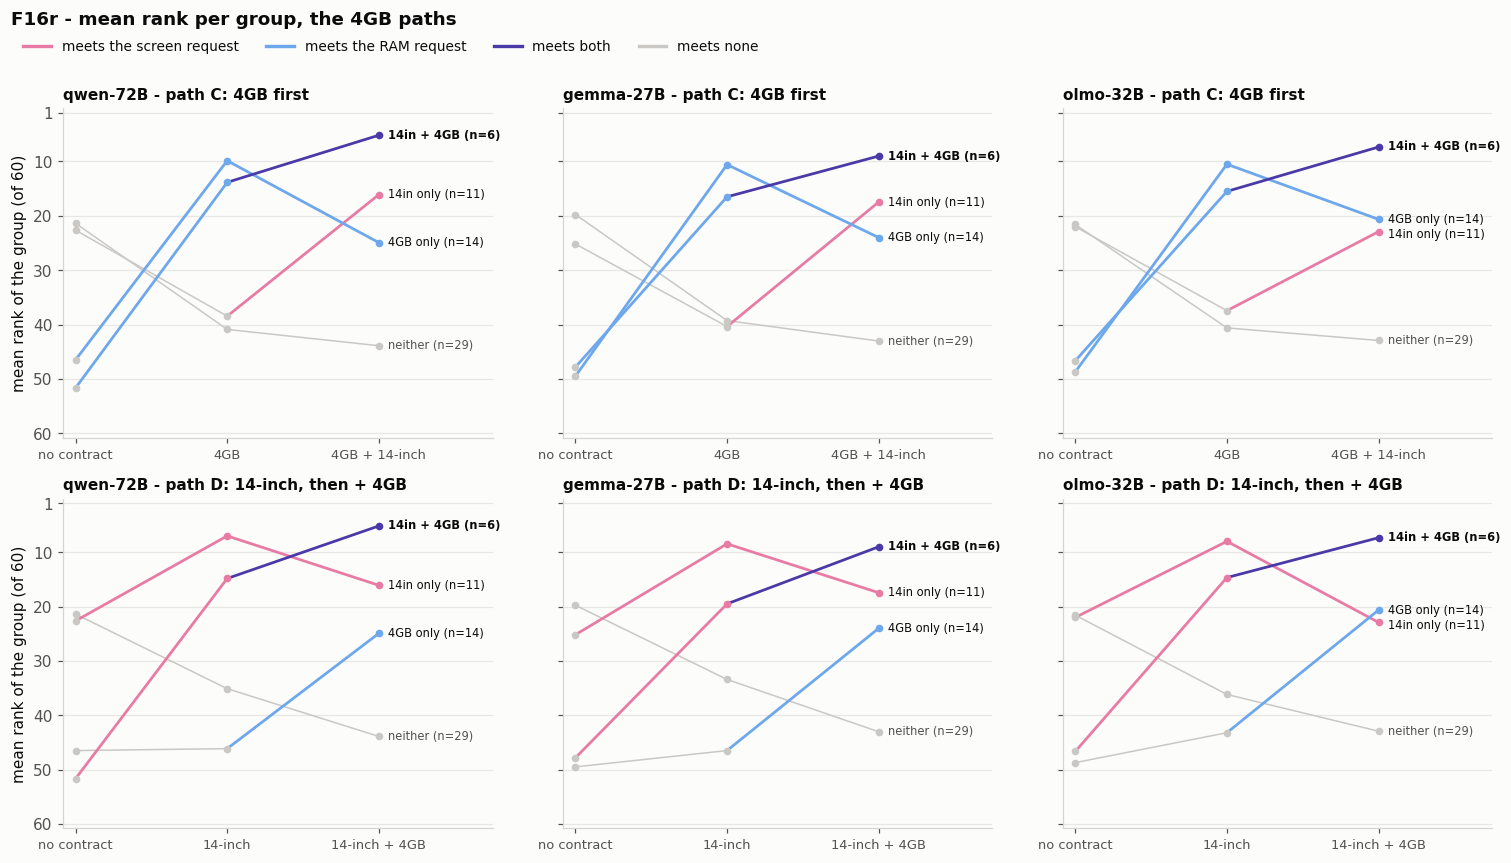

path C: 4GB first - the 6 laptops that meet the full contract (best possible mean rank: 3.5)
    model  mean rank | none  mean rank | 4GB  mean rank | 4GB+14in  in top 10 | none  in top 10 | 4GB  in top 10 | 4GB+14in
 qwen-72B              51.7             13.8                   5.2                 0                3                     5
gemma-27B              47.8             16.5                   9.0                 0                2                     4
 olmo-32B              46.7             15.5                   7.3                 0                1                     4

path D: 14-inch, then + 4GB - the 6 laptops that meet the full contract (best possible mean rank: 3.5)
    model  mean rank | none  mean rank | 14in  mean rank | 14in+4GB  in top 10 | none  in top 10 | 14in  in top 10 | 14in+4GB
 qwen-72B              51.7              14.8                   5.2                 0                 1                     5
gemma-27B              47.8              19.5          

In [9]:
path_grid([PC, PD], "F15r - real laptop ranks (60 laptops), the 4GB paths", "F15r_rank_grid_4GB")
path_grid([PC, PD], "F16r - mean rank per group, the 4GB paths", "F16r_rank_by_group_grid_4GB", grouped=True)
group_table([PC, PD])

# Graph 5 — adherence, feature weights, brand weights

## F11r — adherence when obeying costs

For each contract: the pairs where **exactly one** laptop meets it. They split in two by what the model does
with **no** contract:

- **conflict** — the laptop that meets the contract *loses* without it. Obeying costs.
- **free** — it already wins without it.

The dot = % of the **conflict** pairs where the laptop that meets the contract wins once the contract is in
the prompt. The table adds the free pairs and **κ** on the conflict pairs: 0 = the contract did nothing,
1 = the model is now indifferent, above 1 = it now prefers what was asked.

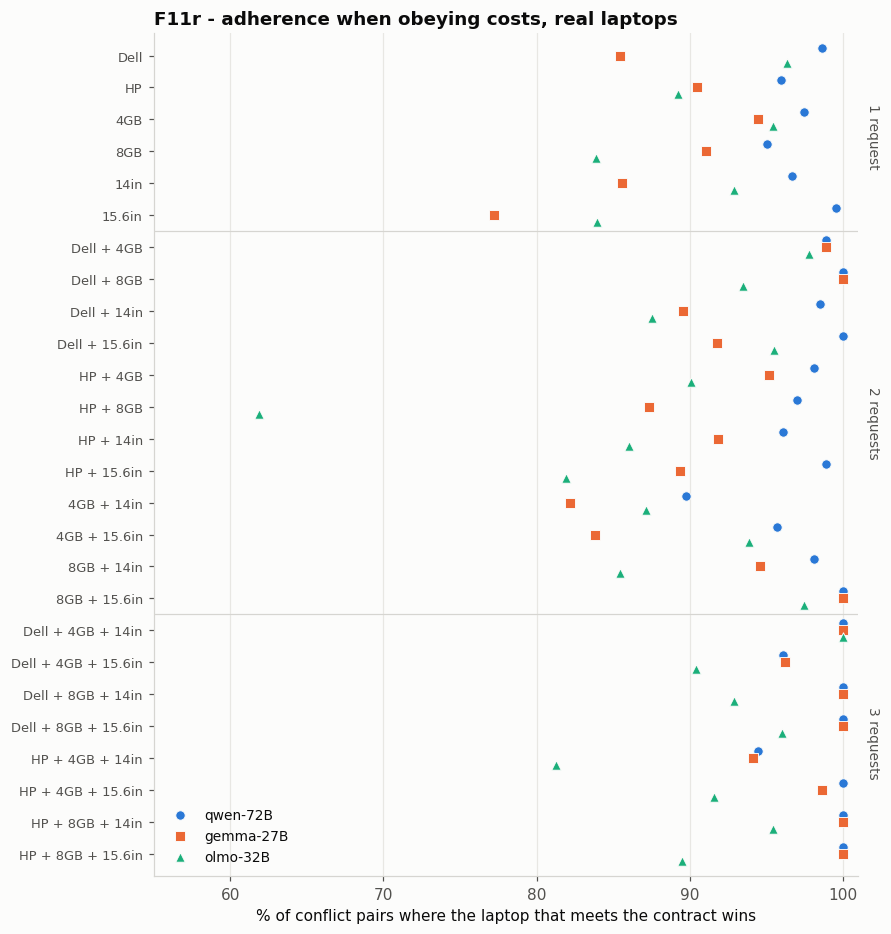

mean over the contracts of each depth
                 n_conflict  conflict_win  free_win     g0     g1  kappa
model     depth                                                         
gemma-27B 1          451.17         87.37    100.00 -15.81  12.18   1.77
          2           76.42         92.04    100.00 -16.08  15.52   1.99
          3           38.25         98.62    100.00 -15.90  19.59   2.26
olmo-32B  1          419.50         90.27     99.35  -3.25   3.92   2.26
          2           72.75         88.17     99.90  -3.29   4.27   2.48
          3           36.00         92.12    100.00  -3.15   5.06   2.92
qwen-72B  1          420.33         97.21    100.00  -7.91  10.45   2.43
          2           73.67         97.58    100.00  -8.21  13.96   3.03
          3           36.50         98.82    100.00  -8.18  16.36   3.42

the 8 lowest cells
    model                             cid  n_conflict  conflict_win  free_win     g0    g1  kappa
 olmo-32B                brand=HP+ram=8GB

In [10]:
rows = []
for m in MODELS:
    D0 = DUEL[(*m, "none")]
    for c in CIDS[1:]:
        con, D1 = parse(c), DUEL[(*m, c)]
        sat = pd.Series({i: met(LVL[i], con) == frozenset(con) for i in IDS})
        s, o = [i for i in IDS if sat[i]], [i for i in IDS if not sat[i]]
        d1, d0 = D1.loc[s, o].values.ravel(), D0.loc[s, o].values.ravel()      # margin of the laptop that meets it
        ok = np.isfinite(d1)
        d1, d0 = d1[ok], d0[ok]
        conf = d0 < 0
        rows.append(dict(model=name(m), cid=c, depth=len(con), pairs=len(d1), n_conflict=int(conf.sum()),
                         conflict_win=100 * (d1[conf] > 0).mean(), free_win=100 * (d1[~conf] > 0).mean(),
                         g0=d0[conf].mean(), g1=d1[conf].mean(), kappa=1 - d1[conf].mean() / d0[conf].mean()))
AD = pd.DataFrame(rows)

order = list(reversed(CIDS[1:]))
fig, ax = plt.subplots(figsize=(8.2, 8.6))
for k, m in enumerate(MODELS):
    t = AD[AD.model == name(m)].set_index("cid").loc[order]
    ax.scatter(t.conflict_win, np.arange(len(order)) + 0.22 * (1 - k), s=38, marker=MODEL_MARK[m], color=MODEL_COLOR[m],
               edgecolor=SURFACE, lw=0.6, zorder=3, label=name(m))
for y in (7.5, 19.5):                                       # between triples / pairs / singles
    ax.axhline(y, color="#d6d5d1", lw=0.8)
for y, lab in [(3.5, "3 requests"), (13.5, "2 requests"), (22.5, "1 request")]:
    ax.text(101.5, y, lab, rotation=270, va="center", ha="left", fontsize=9, color=INK_MUTED)
ax.set_yticks(range(len(order)), [c.replace("brand=", "").replace("ram=", "").replace("screen=", "").replace("-inch", "in").replace("+", " + ") for c in order], fontsize=8.5)
ax.set_xlim(55, 101); ax.set_ylim(-0.7, len(order) - 0.3)
ax.set_xlabel("% of conflict pairs where the laptop that meets the contract wins")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", frameon=False, fontsize=9)
ax.set_title("F11r - adherence when obeying costs, real laptops", loc="left", fontweight="bold")
fig.tight_layout()
save(fig, "F11r_adherence_conflict")
plt.show()

print("mean over the contracts of each depth")
print(AD.groupby(["model", "depth"])[["n_conflict", "conflict_win", "free_win", "g0", "g1", "kappa"]].mean().round(2).to_string())
print("\nthe 8 lowest cells")
print(AD.nsmallest(8, "conflict_win")[["model", "cid", "n_conflict", "conflict_win", "free_win", "g0", "g1", "kappa"]].round(2).to_string(index=False))

## F12r — feature weights next to the positional bias, no contract

The additive fit on the three named features (binned levels). Weights are centred inside each feature, so
0 = the average level. **γ** = how much being shown first moves the answer; positive = the model favours the
first slot. These runs were collected with PMI off, so γ is the fitted intercept.

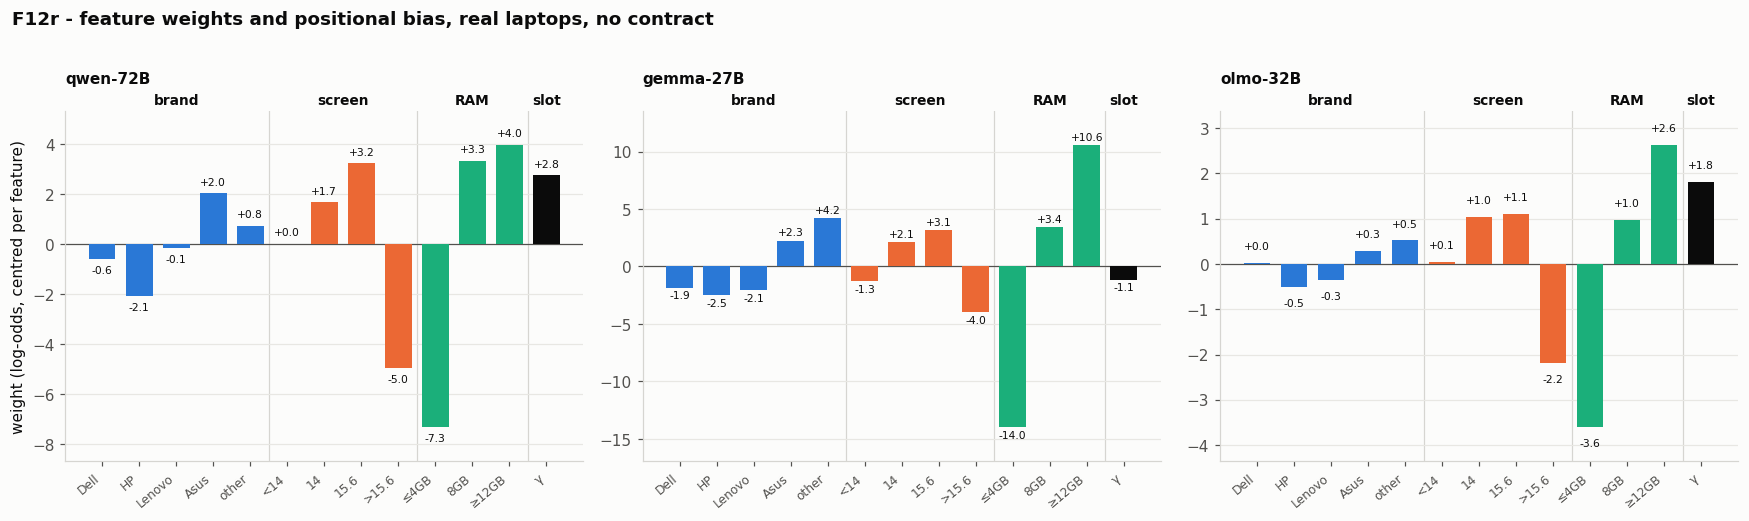

    model  range brand  range screen  range ram  gamma  R2 additive (rows)  R2 per-laptop (rows)
 qwen-72B         4.10          8.21      11.30   2.77                0.60                  0.77
gemma-27B         6.68          7.12      24.57  -1.14                0.60                  0.78
 olmo-32B         1.03          3.30       6.24   1.82                0.64                  0.84


In [11]:
FITS = {(m, c): additive_fit(RUNS[(*m, c)])[0] for m in MODELS for c in ["none", "screen=14-inch", "ram=8GB", "ram=8GB+screen=14-inch"]}
lv = [(ft, l) for ft in FEATS for l in BLEVELS[ft]]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
rows = []
for ax, m in zip(axes, MODELS):
    f = FITS[(m, "none")]
    vals = [f.weights_[ft][l] for ft, l in lv] + [f.gamma_]
    cols = [FEATURE_COLOR[ft] for ft, _ in lv] + [INK]
    x = np.arange(len(vals))
    ax.bar(x, vals, 0.72, color=cols, zorder=2)
    ax.axhline(0, color=INK_MUTED, lw=0.8, zorder=1)
    for xi, v in zip(x, vals):
        ax.text(xi, v + (0.25 if v >= 0 else -0.25), f"{v:+.1f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=7)
    ax.set_xticks(x, [l for _, l in lv] + ["γ"], rotation=40, ha="right", fontsize=8)
    for ft in FEATS:
        idx = [i for i, (ff, _) in enumerate(lv) if ff == ft]
        ax.text(np.mean(idx), 1.01, {"brand": "brand", "screen": "screen", "ram": "RAM"}[ft], transform=ax.get_xaxis_transform(),
                ha="center", va="bottom", fontweight="bold", fontsize=9)
        if idx[0] > 0:
            ax.axvline(idx[0] - 0.5, color="#d6d5d1", lw=0.8, zorder=0)
    ax.axvline(len(lv) - 0.5, color="#d6d5d1", lw=0.8, zorder=0)
    ax.text(len(lv), 1.01, "slot", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontweight="bold", fontsize=9)
    ax.margins(y=0.12)
    ax.grid(axis="x", visible=False)
    ax.set_title(name(m), loc="left", fontsize=10, fontweight="bold", pad=18)
    rows.append({"model": name(m), **{f"range {ft}": f.range(ft) for ft in FEATS}, "gamma": f.gamma_, "R2 additive (rows)": f.r2_,
                 "R2 per-laptop (rows)": R2_ITEM[(*m, "none")]})
axes[0].set_ylabel("weight (log-odds, centred per feature)")
fig.suptitle("F12r - feature weights and positional bias, real laptops, no contract", x=0.01, y=1.02, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "F12r_feature_weights")
plt.show()
print(pd.DataFrame(rows).round(2).to_string(index=False))

## F13r — brand weights across the contracts

No Apple in this set, so the "Apple decay" itself cannot be tested. The figure asks the wider question:
do the brand weights move under contracts that **do not mention brand**?

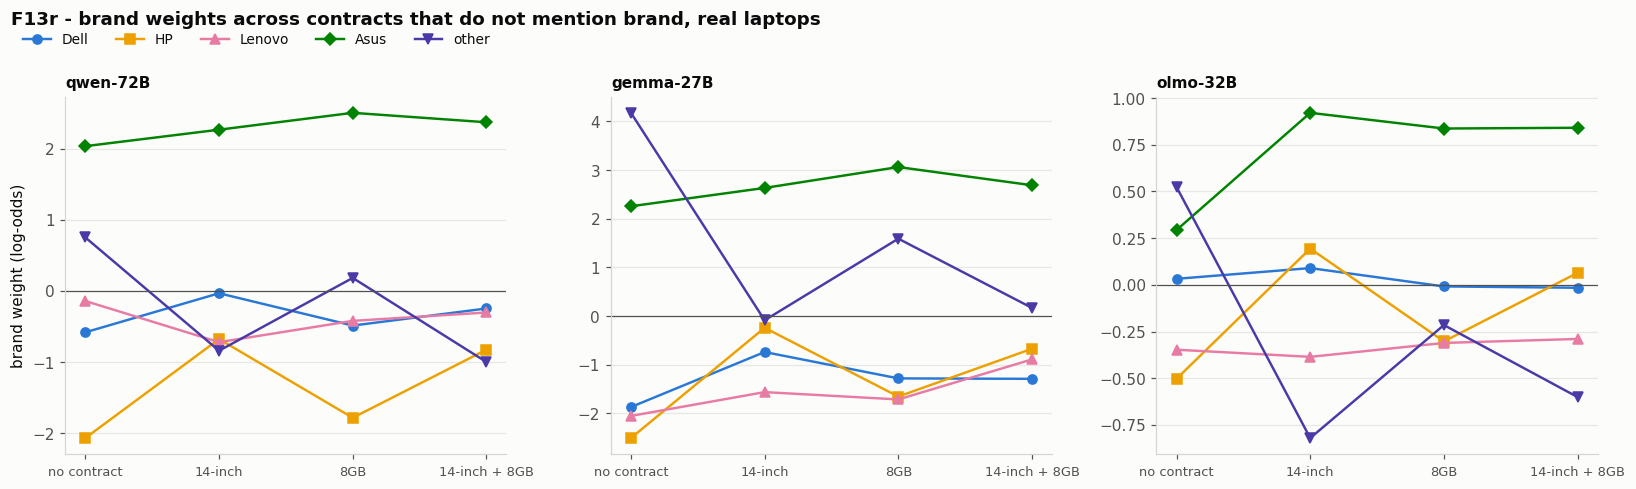

    model  brand  no contract  14-inch   8GB  14-inch + 8GB  move
 qwen-72B   Dell        -0.58    -0.03 -0.49          -0.25  0.34
 qwen-72B     HP        -2.07    -0.68 -1.78          -0.83  1.24
 qwen-72B Lenovo        -0.14    -0.72 -0.42          -0.30 -0.16
 qwen-72B   Asus         2.04     2.27  2.51           2.37  0.34
 qwen-72B  other         0.75    -0.84  0.18          -1.00 -1.75
gemma-27B   Dell        -1.87    -0.74 -1.28          -1.29  0.58
gemma-27B     HP        -2.51    -0.24 -1.65          -0.67  1.83
gemma-27B Lenovo        -2.05    -1.56 -1.71          -0.89  1.16
gemma-27B   Asus         2.26     2.63  3.06           2.69  0.43
gemma-27B  other         4.17    -0.09  1.59           0.17 -4.01
 olmo-32B   Dell         0.03     0.09 -0.01          -0.02 -0.05
 olmo-32B     HP        -0.50     0.19 -0.30           0.06  0.57
 olmo-32B Lenovo        -0.35    -0.39 -0.31          -0.29  0.06
 olmo-32B   Asus         0.29     0.92  0.84           0.84  0.55
 olmo-32B 

In [12]:
G3_CONS = ["none", "screen=14-inch", "ram=8GB", "ram=8GB+screen=14-inch"]
G3_LAB = ["no contract", "14-inch", "8GB", "14-inch + 8GB"]
BRAND_COLOR = dict(zip(BLEVELS["brand"], ["#2a78d6", "#eda100", "#e87ba4", "#008300", "#4a3aa7"]))
BRAND_MARKER = dict(zip(BLEVELS["brand"], ["o", "s", "^", "D", "v"]))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
rows = []
for ax, m in zip(axes, MODELS):
    for b in BLEVELS["brand"]:
        y = [FITS[(m, c)].weights_["brand"][b] for c in G3_CONS]
        ax.plot(range(4), y, "-", marker=BRAND_MARKER[b], color=BRAND_COLOR[b], ms=6, lw=1.6, label=b)
        rows.append({"model": name(m), "brand": b, **dict(zip(G3_LAB, y)), "move": y[-1] - y[0]})
    ax.axhline(0, color=INK_MUTED, lw=0.8)
    ax.set_xticks(range(4), G3_LAB, fontsize=8.5)
    ax.grid(axis="x", visible=False)
    ax.set_title(name(m), loc="left", fontsize=10, fontweight="bold")
axes[0].set_ylabel("brand weight (log-odds)")
fig.tight_layout(rect=(0, 0, 1, 0.9))
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, fontsize=9, ncol=5, loc="lower left", bbox_to_anchor=(0.01, 0.9))
fig.suptitle("F13r - brand weights across contracts that do not mention brand, real laptops", x=0.01, y=1.0, ha="left", fontweight="bold")
save(fig, "F13r_brand_weights")
plt.show()
BW = pd.DataFrame(rows)
print(BW.round(2).to_string(index=False))

# Graph 3 — theoretical vs empirical utility

x = the **additive** fit (brand + screen + RAM, binned: 9 free numbers for 60 laptops). y = one free
utility **per laptop**. On the synthetic set every point sat on the diagonal (R² 0.97–0.996 for qwen-32B).
Here a laptop is much more than its three named features, so the distance from the diagonal is what the
three features do **not** explain.

## F8r — every model, the four contracts of paths A and B

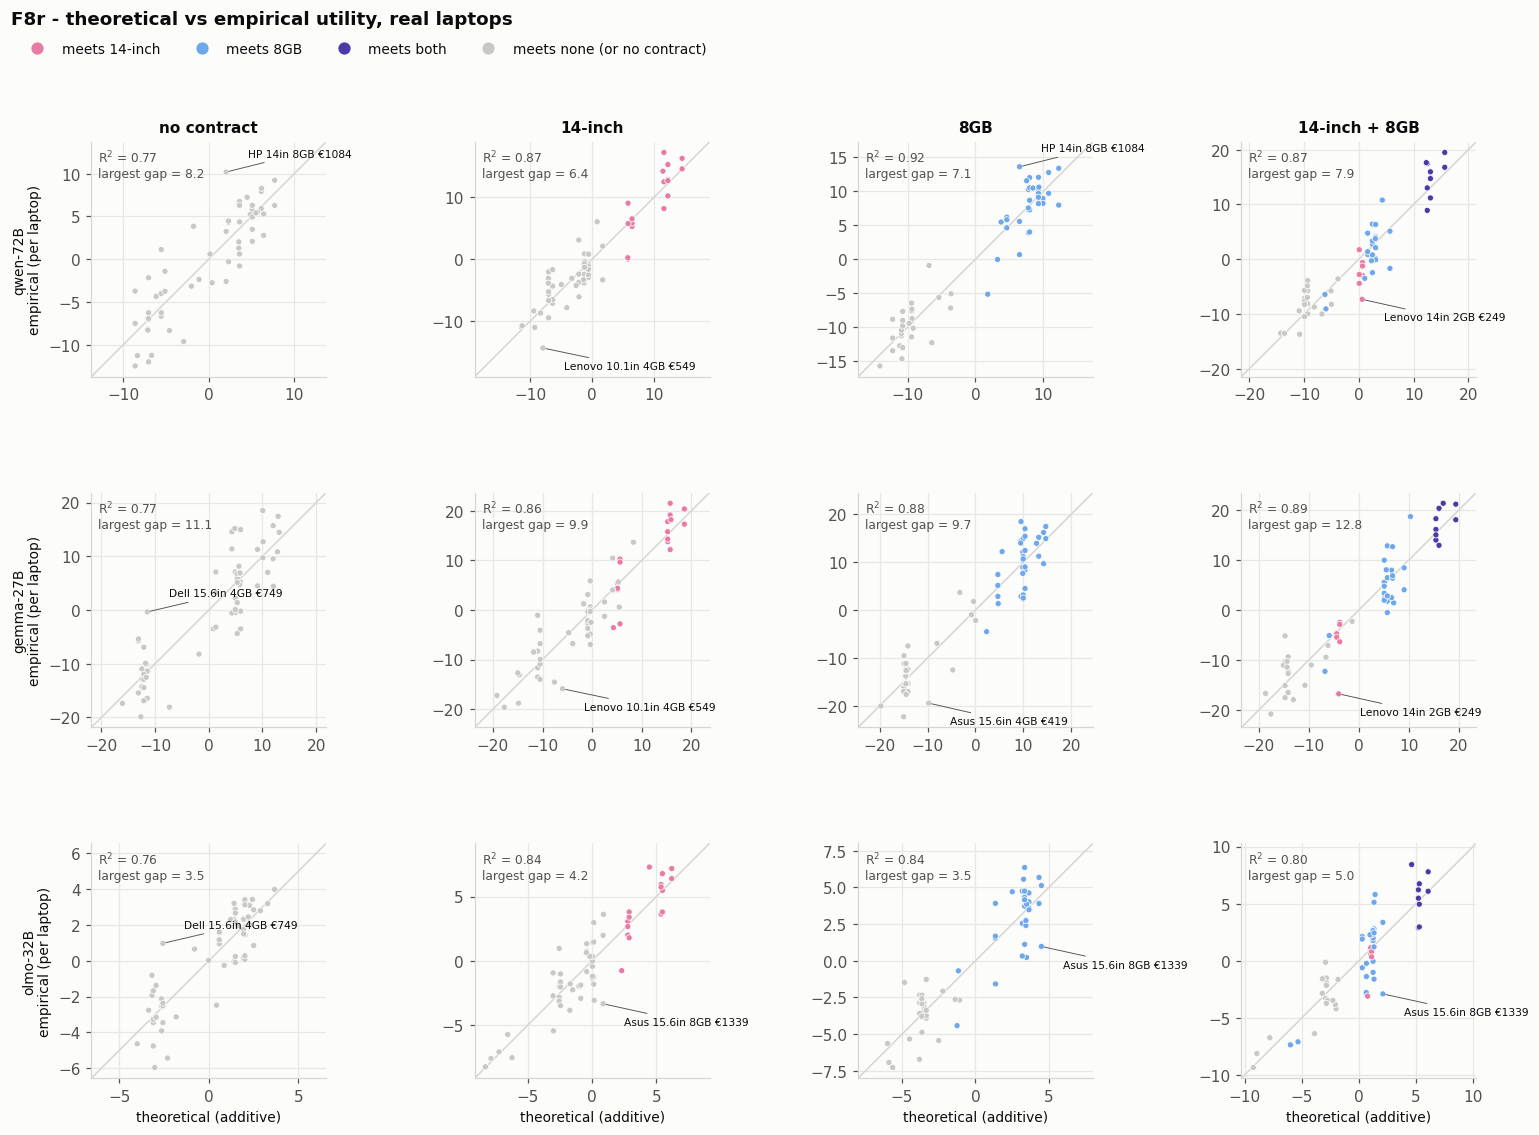

    model      contract  R2 binned (9 numbers)  R2 raw levels (16 numbers)  largest gap  spread of utilities
 qwen-72B   no contract                  0.773                       0.806        8.168               22.688
 qwen-72B       14-inch                  0.874                       0.919        6.407               31.671
 qwen-72B           8GB                  0.919                       0.936        7.128               29.361
 qwen-72B 14-inch + 8GB                  0.870                       0.904        7.927               33.190
gemma-27B   no contract                  0.766                       0.814       11.100               38.397
gemma-27B       14-inch                  0.863                       0.907        9.923               41.153
gemma-27B           8GB                  0.885                       0.915        9.691               40.776
gemma-27B 14-inch + 8GB                  0.894                       0.941       12.752               42.171
 olmo-32B   no cont

In [13]:
def tv_panel(ax, m, cid, n_labels=1, fs=7, ms=16):
    d = RUNS[(*m, cid)]
    th, em = additive_fit(d)[1], UTIL[(*m, cid)]
    res = em - th
    r2 = 1 - (res ** 2).sum() / ((em - em.mean()) ** 2).sum()
    lim = max(th.abs().max(), em.abs().max()) * 1.1
    ax.plot([-lim, lim], [-lim, lim], color="#d6d5d1", lw=1, zorder=1)
    con = parse(cid)
    col = [MIX[met(LVL[i], {f: v for f, v in con.items() if f in REQ_COLOR})] for i in IDS]
    ax.scatter(th, em, s=ms, c=col, edgecolors=SURFACE, linewidths=0.5, zorder=2)
    for k, i in enumerate(res.abs().sort_values(ascending=False).index[:n_labels]):
        ax.annotate(short(i), (th[i], em[i]), xytext=(14, -12 if res[i] < 0 else 12), textcoords="offset points",
                    fontsize=fs, color=INK, va="center", arrowprops=dict(arrowstyle="-", color=INK_MUTED, lw=0.6))
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.text(0.03, 0.97, f"R$^2$ = {r2:.2f}\nlargest gap = {res.abs().max():.1f}", transform=ax.transAxes, va="top",
            fontsize=fs + 1, color=INK_MUTED)
    return r2, res.abs().max()


fig, axes = plt.subplots(3, 4, figsize=(14, 10.6))
rows = []
for r, m in enumerate(MODELS):
    for ci, (c, lab) in enumerate(zip(G3_CONS, G3_LAB)):
        ax = axes[r, ci]
        r2, gap = tv_panel(ax, m, c)
        f_raw, u_raw = additive_fit(RUNS[(*m, c)], binned=False)
        em = UTIL[(*m, c)]
        rows.append({"model": name(m), "contract": lab, "R2 binned (9 numbers)": r2,
                     "R2 raw levels (16 numbers)": 1 - ((em - u_raw) ** 2).sum() / (em ** 2).sum(),
                     "largest gap": gap, "spread of utilities": em.max() - em.min()})
        if r == 0:
            ax.set_title(lab, fontsize=10, fontweight="bold")
        if ci == 0:
            ax.set_ylabel(f"{name(m)}\nempirical (per laptop)", fontsize=9)
        if r == 2:
            ax.set_xlabel("theoretical (additive)", fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.95))
hs = [Line2D([], [], ls="", marker="o", ms=7, color=c, label=l) for c, l in
      [(PINK, "meets 14-inch"), (SKY, "meets 8GB"), (PURPLE, "meets both"), (GRAY, "meets none (or no contract)")]]
fig.legend(handles=hs, loc="lower left", ncol=4, bbox_to_anchor=(0.01, 0.95), frameon=False, fontsize=9)
fig.suptitle("F8r - theoretical vs empirical utility, real laptops", x=0.01, y=1.0, ha="left", fontweight="bold")
save(fig, "F8r_theory_vs_empirical")
plt.show()
TV = pd.DataFrame(rows)
print(TV.round(3).to_string(index=False))

### What the three features miss

The same per-laptop utility (no contract) against things the contract never names. Spearman correlation
over the 60 laptops.

In [14]:
X = pd.DataFrame({"price (€)": ITEMS.Price_euros, "RAM (GB)": ITEMS.Ram.str.replace("GB", "").astype(float),
                  "screen (inch)": ITEMS.Inches, "weight (kg)": ITEMS.Weight.str.replace("kg", "").astype(float),
                  "has SSD": ITEMS.Memory.str.contains("SSD|Flash").astype(float)})
print(pd.DataFrame({name(m): {k: st.spearmanr(UTIL[(*m, "none")], X[k])[0] for k in X} for m in MODELS}).round(2).to_string())
D0 = {m: DUEL[(*m, "none")] for m in MODELS}
ram, price = X["RAM (GB)"], X["price (€)"]
rows = []
for m in MODELS:
    D = D0[m]
    iu = np.triu_indices(N, 1)
    dv = D.values[iu]; dr = (ram.values[:, None] - ram.values[None, :])[iu]; dp = (price.values[:, None] - price.values[None, :])[iu]
    rows.append({"model": name(m), "more RAM wins %": 100 * (np.sign(dv[dr != 0]) == np.sign(dr[dr != 0])).mean(),
                 "pairs (RAM differs)": int((dr != 0).sum()),
                 "pricier wins %": 100 * (np.sign(dv[dp != 0]) == np.sign(dp[dp != 0])).mean(),
                 "same RAM: pricier wins %": 100 * (np.sign(dv[(dr == 0) & (dp != 0)]) == np.sign(dp[(dr == 0) & (dp != 0)])).mean()})
print()
print(pd.DataFrame(rows).round(1).to_string(index=False))

               qwen-72B  gemma-27B  olmo-32B
price (€)          0.29       0.55      0.45
RAM (GB)           0.68       0.80      0.73
screen (inch)      0.03       0.13      0.01
weight (kg)        0.10       0.21      0.10
has SSD            0.44       0.45      0.47

    model  more RAM wins %  pairs (RAM differs)  pricier wins %  same RAM: pricier wins %
 qwen-72B             86.3                 1046            63.3                      45.0
gemma-27B             94.9                 1046            70.3                      49.0
 olmo-32B             89.1                 1046            64.5                      43.5


# Graph 4 — Borda vs Bradley-Terry

x = **Borda** rank: how many rivals the laptop beats (D > 0), no model fitted. y = BT rank, for the
per-laptop fit and for the additive fit. Under `14-inch + 8GB` a laptop met only about 17 of its 59 rivals,
so Borda there is the **share** of the rivals it met that it beat.

## F10r — every model, the four contracts

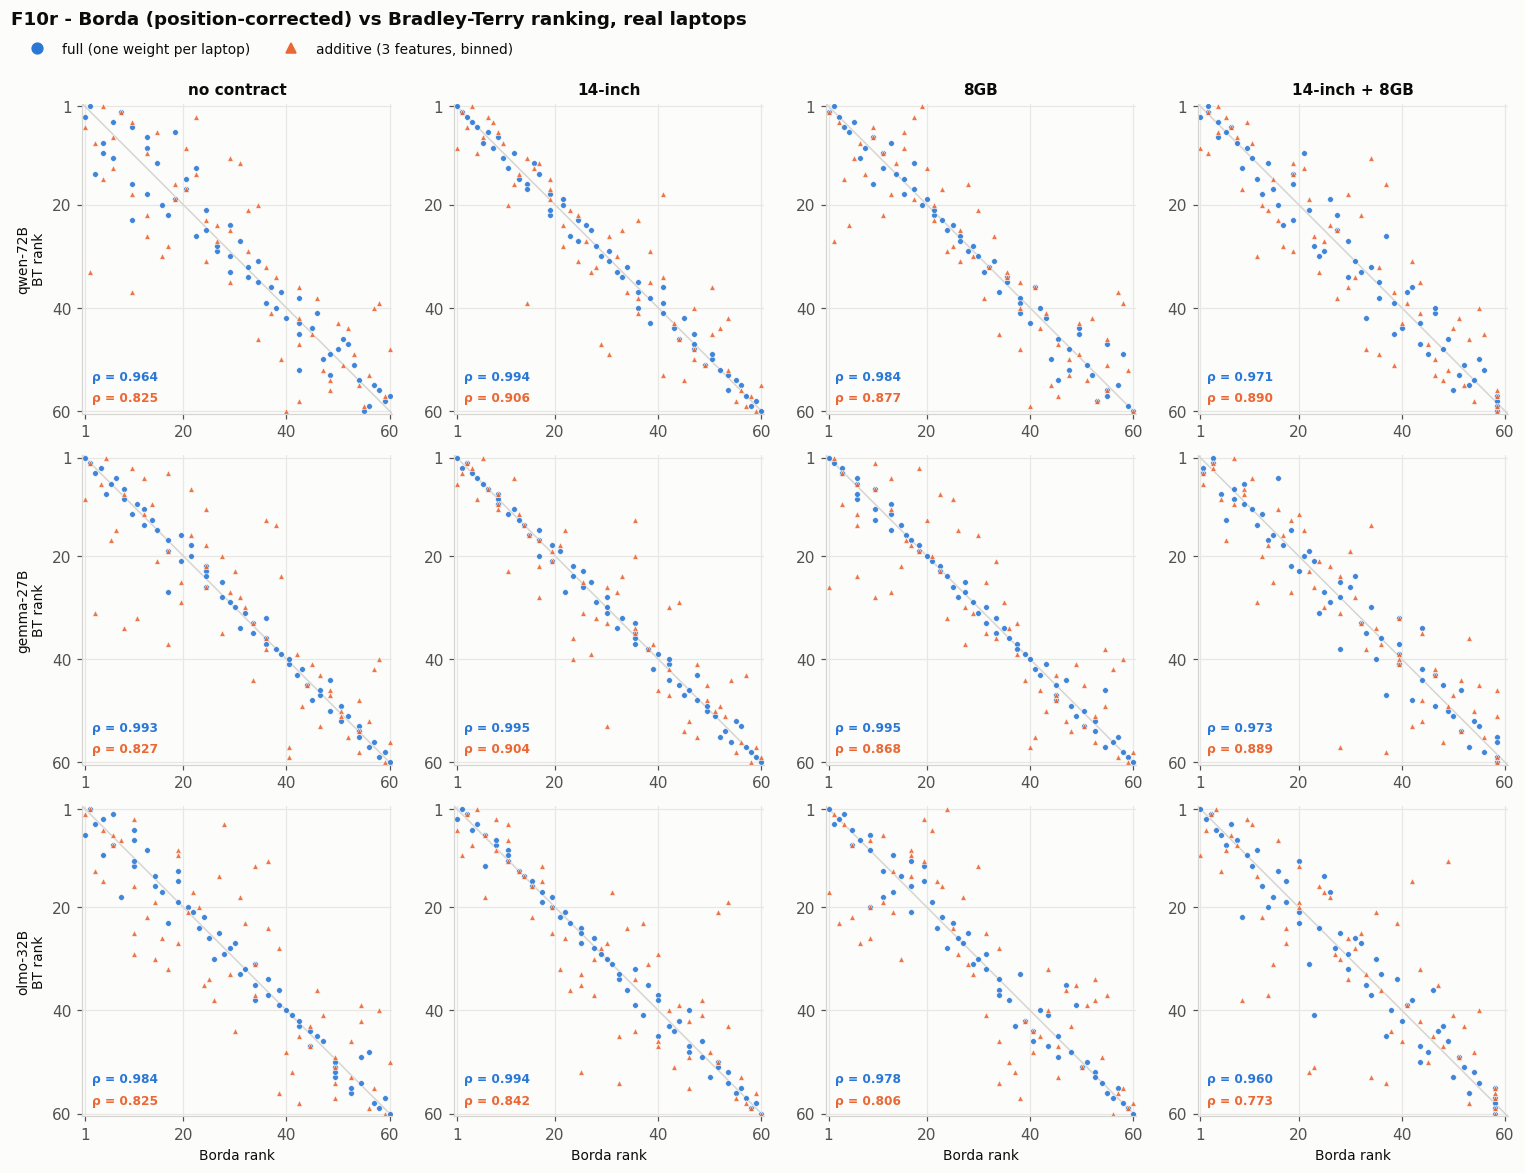

    model      contract  rho full  rho additive
 qwen-72B   no contract     0.964         0.825
 qwen-72B       14-inch     0.994         0.906
 qwen-72B           8GB     0.984         0.877
 qwen-72B 14-inch + 8GB     0.971         0.890
gemma-27B   no contract     0.993         0.827
gemma-27B       14-inch     0.995         0.904
gemma-27B           8GB     0.995         0.868
gemma-27B 14-inch + 8GB     0.973         0.889
 olmo-32B   no contract     0.984         0.825
 olmo-32B       14-inch     0.994         0.842
 olmo-32B           8GB     0.978         0.806
 olmo-32B 14-inch + 8GB     0.960         0.773


In [15]:
BT_TYPES = [("full (one weight per laptop)", "#2a78d6", "o"), ("additive (3 features, binned)", "#eb6834", "^")]


def borda_panel(ax, m, cid, ms=14, fs=8):
    D = DUEL[(*m, cid)]
    bs = ((D > 0).sum(axis=1) / D.notna().sum(axis=1))
    xr = rank_desc(bs, ties="average")
    us = [UTIL[(*m, cid)], additive_fit(RUNS[(*m, cid)])[1]]
    out = []
    ax.plot([0.5, N + 0.5], [0.5, N + 0.5], color="#d6d5d1", lw=1, zorder=1)
    for (lab, col, mk), u in zip(BT_TYPES, us):
        ax.scatter(xr, rank_desc(u), s=ms, color=col, marker=mk, edgecolor=SURFACE, lw=0.4, zorder=2, alpha=0.9)
        out.append(st.spearmanr(bs, u)[0])
    ax.set_xlim(0.5, N + 0.5); ax.set_ylim(N + 0.5, 0.5); ax.set_aspect("equal")
    ax.set_xticks([1, 20, 40, 60]); ax.set_yticks([1, 20, 40, 60])
    for i, ((lab, col, _), rho) in enumerate(zip(BT_TYPES, out)):
        ax.text(0.03, 0.03 + 0.07 * (1 - i), f"ρ = {rho:.3f}", transform=ax.transAxes, va="bottom", fontsize=fs,
                color=col, fontweight="bold")
    return out


fig, axes = plt.subplots(3, 4, figsize=(14, 10.6))
rows = []
for r, m in enumerate(MODELS):
    for ci, (c, lab) in enumerate(zip(G3_CONS, G3_LAB)):
        rho = borda_panel(axes[r, ci], m, c)
        rows.append({"model": name(m), "contract": lab, "rho full": rho[0], "rho additive": rho[1]})
        if r == 0:
            axes[r, ci].set_title(lab, fontsize=10, fontweight="bold")
        if ci == 0:
            axes[r, ci].set_ylabel(f"{name(m)}\nBT rank", fontsize=9)
        if r == 2:
            axes[r, ci].set_xlabel("Borda rank", fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.95))
hs = [Line2D([], [], ls="", marker=mk, ms=7, color=col, label=lab) for lab, col, mk in BT_TYPES]
fig.legend(handles=hs, loc="lower left", ncol=2, bbox_to_anchor=(0.01, 0.95), frameon=False, fontsize=9)
fig.suptitle("F10r - Borda (position-corrected) vs Bradley-Terry ranking, real laptops", x=0.01, y=1.0, ha="left", fontweight="bold")
save(fig, "F10r_borda_vs_bt")
plt.show()
print(pd.DataFrame(rows).round(3).to_string(index=False))

## T1r — how often the slot decides

Per pair: **P** = the push to the first slot, **D** = the preference. "The slot decides" = the same slot wins
in both orders (|P| > |D|). Synthetic set: 15–30% of all comparisons.

In [16]:
rows = []
for m in MODELS:
    for lab, cs in [("no contract", ["none"]), ("1 request", CIDS[1:7]), ("2 requests", CIDS[7:19]), ("3 requests", CIDS[19:])]:
        dec, gam = [], []
        for c in cs:
            d = RUNS[(*m, c)]
            M = np.full((N, N), np.nan)
            M[d.a_id.map(POS).values, d.b_id.map(POS).values] = (d.score_a - d.score_b).values
            iu = np.triu_indices(N, 1)
            Dv, Pv = ((M - M.T) / 2)[iu], ((M + M.T) / 2)[iu]
            ok = np.isfinite(Dv)
            dec.append(100 * (np.abs(Pv[ok]) > np.abs(Dv[ok])).mean()); gam.append(GAMMA[(*m, c)])
        rows.append({"model": name(m), "contracts": lab, "slot decides %": np.mean(dec), "gamma (mean)": np.mean(gam),
                     "gamma min": np.min(gam), "gamma max": np.max(gam)})
print(pd.DataFrame(rows).round(2).to_string(index=False))

    model   contracts  slot decides %  gamma (mean)  gamma min  gamma max
 qwen-72B no contract           29.44          2.77       2.77       2.77
 qwen-72B   1 request           19.93          0.75      -0.91       1.37
 qwen-72B  2 requests           15.38          0.06      -1.41       0.92
 qwen-72B  3 requests           12.28         -0.22      -0.89       0.56
gemma-27B no contract           10.68         -1.14      -1.14      -1.14
gemma-27B   1 request           15.49          0.52      -1.44       2.91
gemma-27B  2 requests           13.28         -0.22      -3.48       1.40
gemma-27B  3 requests           12.25         -1.51      -3.05      -0.38
 olmo-32B no contract           26.67          1.82       1.82       1.82
 olmo-32B   1 request           19.21          1.29       1.05       1.51
 olmo-32B  2 requests           15.30          1.02       0.43       1.46
 olmo-32B  3 requests           13.30          0.62       0.35       0.88


# figs4nir2 B — the user's laptop across contracts

A **user** wants one full spec, for example Dell + 14-inch + 8GB. The 8 specs of the design give 8 users.
The user can tell the model 0, 1, 2 or 3 of the three attributes, in any order: 6 **paths** per user.
y = the rank, in the model's order, of the **best laptop that has the user's full spec** (3 to 6 laptops have
it). Rank 1 = the model's first pick is a laptop the user wants.

Bold = the best path (closest to the top, soonest), pale = the other five. The marker says which attribute
was added at that step.

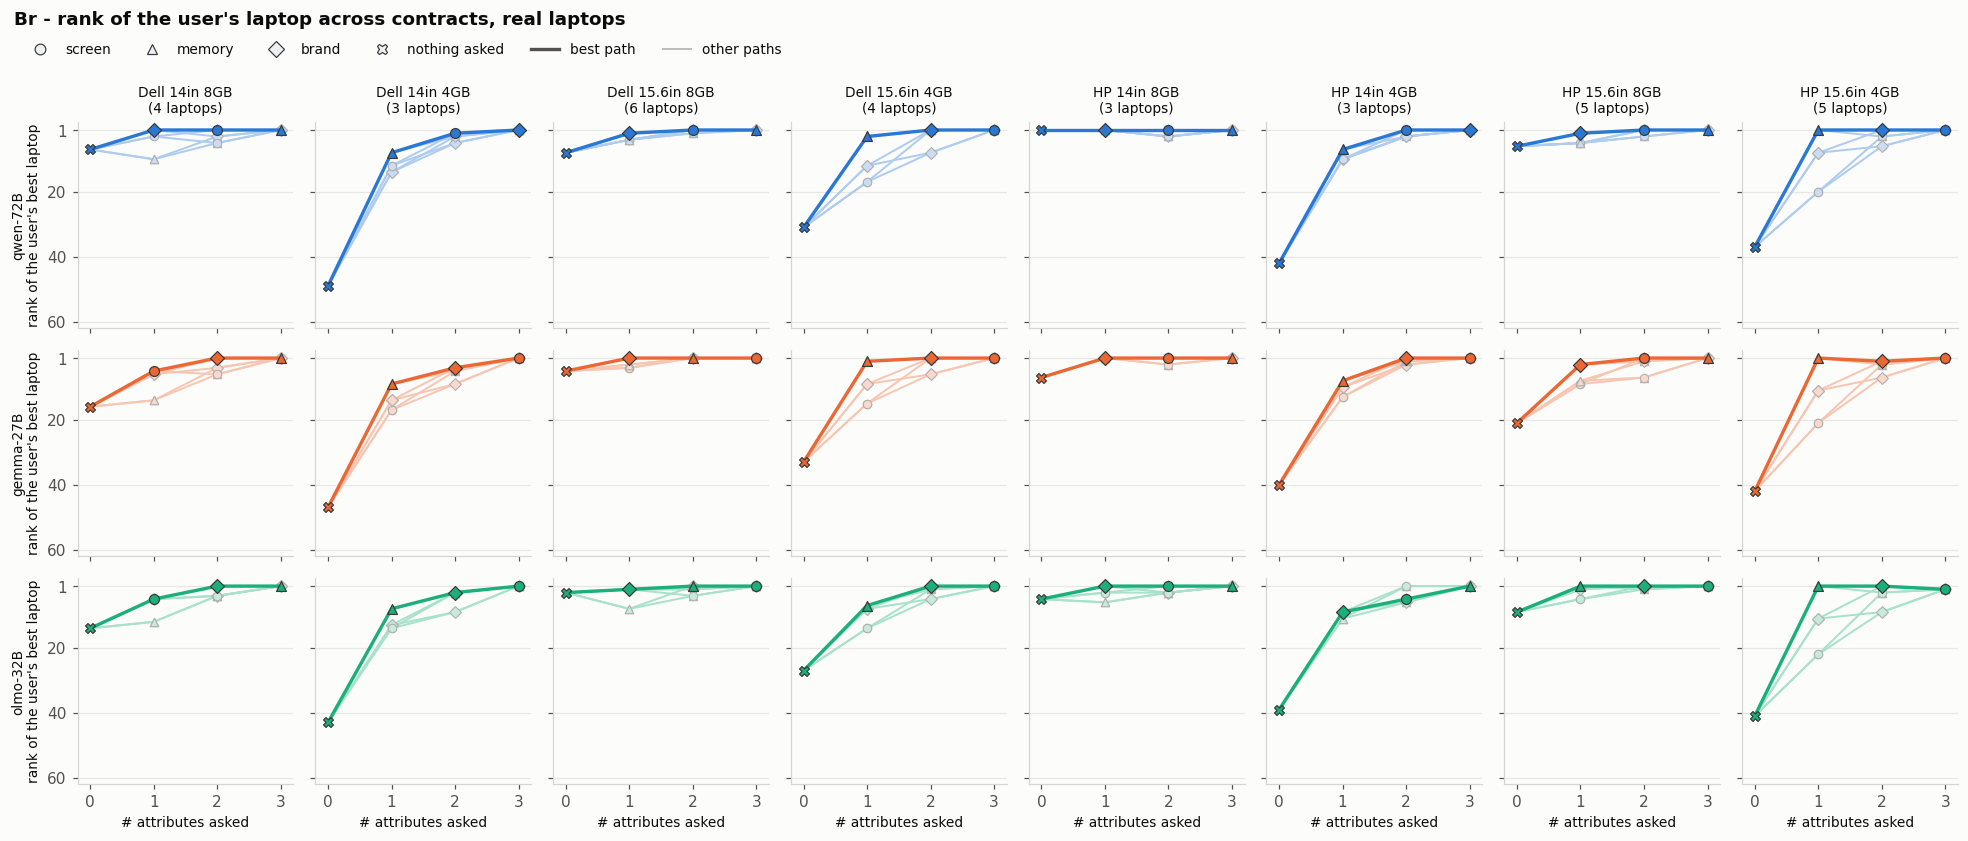

    model            user  k=0               best path  best k=1  best k=2  worst k=1  worst k=2  k=3  mean rank k=3
 qwen-72B   Dell 14in 8GB  7.0 brand > screen > memory       1.0       1.0       10.0        5.0  1.0            2.5
 qwen-72B   Dell 14in 4GB 49.0 memory > screen > brand       8.0       2.0       14.0        5.0  1.0            2.0
 qwen-72B Dell 15.6in 8GB  8.0 brand > screen > memory       2.0       1.0        4.0        2.0  1.0            3.5
 qwen-72B Dell 15.6in 4GB 31.0 memory > brand > screen       3.0       1.0       17.0        8.0  1.0            4.0
 qwen-72B     HP 14in 8GB  1.0 brand > screen > memory       1.0       1.0        1.0        3.0  1.0            2.0
 qwen-72B     HP 14in 4GB 42.0 memory > screen > brand       7.0       1.0       10.0        3.0  1.0            2.7
 qwen-72B   HP 15.6in 8GB  6.0 brand > screen > memory       2.0       1.0        5.0        3.0  1.0            3.0
 qwen-72B   HP 15.6in 4GB 37.0 memory > brand > screen       1.0

In [17]:
USERS = [{"brand": b, "screen": s, "ram": r} for b in ("Dell", "HP") for s in ("14-inch", "15.6-inch") for r in ("8GB", "4GB")]
PATHS = list(itertools.permutations(FEATS))
MARK = {"screen": "o", "ram": "^", "brand": "D"}
MARK_NAME = {"screen": "screen", "ram": "memory", "brand": "brand"}


def ulabel(u):
    return f"{u['brand']} {u['screen'].replace('-inch', 'in')} {u['ram']}"


def targets(u):
    return [i for i in IDS if all(LVL[i][f] == v for f, v in u.items())]


def step(m, u, p, k):
    """Best rank among the user's laptops, and their mean rank, after the first k attributes of path p."""
    r = RANK[m][cid_of({f: u[f] for f in p[:k]})].loc[targets(u)]
    return r.min(), r.mean()


def path_points(m, u, p):
    return np.array([step(m, u, p, k)[0] for k in range(4)])


def best_path(m, u):
    return min(PATHS, key=lambda p: tuple(x for k in (1, 2) for x in step(m, u, p, k)))


def pale(color, t=0.62):
    c = np.array(to_rgb(color))
    return tuple(c + (1 - c) * t)


def user_panel(ax, m, u, col):
    pts = {p: path_points(m, u, p) for p in PATHS}
    best = best_path(m, u)
    for p in PATHS:
        if p == best:
            continue
        ax.plot(range(4), pts[p], color=pale(col), lw=1.3, zorder=2, solid_capstyle="round")
        for k in (1, 2, 3):
            ax.scatter(k, pts[p][k], marker=MARK[p[k - 1]], s=30, zorder=3, color=pale(col, 0.75), edgecolor=pale("#3a3a38", 0.6), lw=0.7)
    ax.plot(range(4), pts[best], color=col, lw=2.2, zorder=4, solid_capstyle="round")
    for k in (1, 2, 3):
        ax.scatter(k, pts[best][k], marker=MARK[best[k - 1]], s=42, zorder=6, color=col, edgecolor="#3a3a38", lw=0.8)
    ax.scatter(0, pts[best][0], marker="X", s=42, zorder=6, color=col, edgecolor="#3a3a38", lw=0.8)
    ax.set_xlim(-0.2, 3.2); ax.set_ylim(N + 2, -1.5)
    ax.set_xticks(range(4)); ax.set_yticks([1, 20, 40, 60])
    ax.grid(axis="x", visible=False)
    return pts, best


fig, axes = plt.subplots(3, 8, figsize=(18, 7.6), sharey=True, sharex=True)
rows = []
for r, m in enumerate(MODELS):
    for j, u in enumerate(USERS):
        ax = axes[r, j]
        pts, best = user_panel(ax, m, u, MODEL_COLOR[m])
        if r == 0:
            ax.set_title(f"{ulabel(u)}\n({len(targets(u))} laptops)", fontsize=9)
        worst = max(PATHS, key=lambda p: (pts[p][1], pts[p][2]))
        rows.append({"model": name(m), "user": ulabel(u), "k=0": pts[best][0],
                     "best path": " > ".join(MARK_NAME[f] for f in best), "best k=1": pts[best][1], "best k=2": pts[best][2],
                     "worst k=1": max(pts[p][1] for p in PATHS), "worst k=2": max(pts[p][2] for p in PATHS),
                     "k=3": pts[best][3], "mean rank k=3": step(m, u, best, 3)[1]})
    axes[r, 0].set_ylabel(f"{name(m)}\nrank of the user's best laptop", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("# attributes asked", fontsize=9)
hm = [Line2D([], [], marker=MARK[f], ls="", ms=7, color="#eef0f3", markeredgecolor="#3a3a38", mew=0.8, label=MARK_NAME[f]) for f in ("screen", "ram", "brand")]
hm += [Line2D([], [], marker="X", ls="", ms=7, color="#eef0f3", markeredgecolor="#3a3a38", mew=0.8, label="nothing asked"),
       Line2D([], [], color="#52514e", lw=2.2, label="best path"), Line2D([], [], color=pale("#52514e"), lw=1.3, label="other paths")]
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.legend(handles=hm, loc="lower left", ncol=6, bbox_to_anchor=(0.01, 0.93), frameon=False, fontsize=9)
fig.suptitle("Br - rank of the user's laptop across contracts, real laptops", x=0.01, y=1.0, ha="left", fontweight="bold")
save(fig, "Br_contract_paths")
plt.show()
UP = pd.DataFrame(rows)
print(UP.round(1).to_string(index=False))
print("\nmean over the 8 users")
print(UP.groupby("model")[["k=0", "best k=1", "worst k=1", "best k=2", "worst k=2", "k=3", "mean rank k=3"]].mean().round(1).to_string())
print("\nfirst attribute of the best path:", UP.groupby("model")["best path"].apply(lambda s: s.str.split(" > ").str[0].value_counts().to_dict()).to_dict())